# 1.0 Exploración de datos MiBici
Exploración de dos meses del rango (jul-2025, inicio del entrenamiento, y sep-2026, fin del test) y de la nomenclatura de estaciones, para confirmar columnas, codificación, tamaños y patrones de uso, y para calibrar la etiqueta de P2. Solo se muestran agregados; no se imprimen registros individuales.

In [12]:
import re
import unicodedata

import matplotlib.pyplot as plt
import pandas as pd
import requests

from mibici_mlops.config import RAW_DATA_DIR

URLS = {
    "2025_07": "https://mibici.net/site/assets/files/108898/datos_abiertos_2025_07.csv",
    "2026_09": "https://mibici.net/site/assets/files/131825/datos_abiertos_2026_09.csv",
    "nomenclatura": "https://mibici.net/site/assets/files/1118/nomenclatura_2026_09.csv",
}
RAW_DATA_DIR.mkdir(parents=True, exist_ok=True)

## Descarga y lectura

In [13]:
HEADERS = {
    "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/141.0 Safari/537.36",
    "Accept": "text/csv,text/plain,*/*",
    "Accept-Language": "es-MX,es;q=0.9",
    "Referer": "https://mibici.net/es/datos-abiertos/",
}

def descargar(url):
    destino = RAW_DATA_DIR / url.split("/")[-1]
    if not destino.exists():
        r = requests.get(url, headers=HEADERS, timeout=300)
        r.raise_for_status()
        destino.write_bytes(r.content)
    print(f"{destino.name}: {destino.stat().st_size / 1e6:.1f} MB")
    return destino


archivos = {k: descargar(u) for k, u in URLS.items()}

datos_abiertos_2025_07.csv: 31.9 MB
datos_abiertos_2026_09.csv: 42.6 MB
nomenclatura_2026_09.csv: 0.0 MB


In [14]:
def leer_csv(ruta):
    for enc in ["utf-8-sig", "latin-1"]:
        try:
            df = pd.read_csv(ruta, encoding=enc, low_memory=False)
            print(f"{ruta.name}: encoding={enc}, filas={len(df):,}, columnas={df.shape[1]}")
            return df
        except UnicodeDecodeError:
            continue


crudos = {k: leer_csv(archivos[k]) for k in ["2025_07", "2026_09"]}
nom_crudo = leer_csv(archivos["nomenclatura"])

for k, df in crudos.items():
    print(f"\n{k}:\n{df.dtypes.to_string()}")
print(f"\nnomenclatura:\n{nom_crudo.dtypes.to_string()}")

datos_abiertos_2025_07.csv: encoding=latin-1, filas=368,186, columnas=8
datos_abiertos_2026_09.csv: encoding=utf-8-sig, filas=490,056, columnas=8
nomenclatura_2026_09.csv: encoding=utf-8-sig, filas=484, columnas=5

2025_07:
Viaje_Id               int64
Usuario_Id             int64
Genero                   str
Año_de_nacimiento    float64
Inicio_del_viaje         str
Fin_del_viaje            str
Origen_Id              int64
Destino_Id             int64

2026_09:
Viaje_Id               int64
Usuario_Id             int64
Genero                   str
Año_de_nacimiento    float64
Inicio_del_viaje         str
Fin_del_viaje            str
Origen_Id              int64
Destino_Id             int64

nomenclatura:
id              int64
name              str
latitude      float64
longitude     float64
dpcapacity      int64


## Normalización de columnas y fechas
Nombres en snake_case sin acentos y fechas como datetime. Este mapeo es el esquema limpio que replicará la ingesta en `dataset.py`.

In [15]:
def snake(col):
    col = unicodedata.normalize("NFKD", str(col)).encode("ascii", "ignore").decode()
    return re.sub(r"[^0-9a-zA-Z]+", "_", col).strip("_").lower()


MAPEO = {
    "ano_de_nacimiento": "anio_nacimiento",
    "a_o_de_nacimiento": "anio_nacimiento",
    "inicio_del_viaje": "inicio_viaje",
    "fin_del_viaje": "fin_viaje",
}


def normalizar(df):
    df = df.rename(columns=lambda c: MAPEO.get(snake(c), snake(c)))
    for c in ["inicio_viaje", "fin_viaje"]:
        df[c] = pd.to_datetime(df[c], errors="coerce")
    return df


viajes = {k: normalizar(df) for k, df in crudos.items()}
for k, df in viajes.items():
    dur = (df["fin_viaje"] - df["inicio_viaje"]).dt.total_seconds() / 60
    print(k, list(df.columns))
    print("  fechas nulas:", df[["inicio_viaje", "fin_viaje"]].isna().sum().to_dict())
    print("  rango inicio:", df["inicio_viaje"].min(), "→", df["inicio_viaje"].max())
    print("  duración (min):", dur.describe(percentiles=[0.01, 0.5, 0.99]).round(1).to_dict())
    print("  duración negativa:", (dur < 0).sum(), "| mayor a 24 h:", (dur > 1440).sum())

2025_07 ['viaje_id', 'usuario_id', 'genero', 'anio_nacimiento', 'inicio_viaje', 'fin_viaje', 'origen_id', 'destino_id']
  fechas nulas: {'inicio_viaje': 0, 'fin_viaje': 0}
  rango inicio: 2025-07-01 00:00:08 → 2025-07-31 23:59:46
  duración (min): {'count': 368186.0, 'mean': 11.2, 'std': 20.9, 'min': 0.0, '1%': 0.3, '50%': 9.7, '99%': 32.5, 'max': 11500.8}
  duración negativa: 0 | mayor a 24 h: 2
2026_09 ['viaje_id', 'usuario_id', 'genero', 'anio_nacimiento', 'inicio_viaje', 'fin_viaje', 'origen_id', 'destino_id']
  fechas nulas: {'inicio_viaje': 0, 'fin_viaje': 0}
  rango inicio: 2026-09-01 00:00:59 → 2026-09-30 23:59:48
  duración (min): {'count': 490056.0, 'mean': 9.8, 'std': 8.7, 'min': 0.0, '1%': 0.2, '50%': 8.4, '99%': 32.4, 'max': 2166.7}
  duración negativa: 0 | mayor a 24 h: 1


In [16]:
nom = nom_crudo.rename(columns=snake)
col_id = next(c for c in ["id", "estacion_id", "id_estacion"] if c in nom.columns)
col_cap = next(c for c in nom.columns if any(p in c for p in ["capac", "anclaje", "slot"]))
nom = nom.rename(columns={col_id: "estacion_id", col_cap: "capacidad"})
print(list(nom.columns))
print("estaciones en nomenclatura:", nom["estacion_id"].nunique())
print("capacidad:", nom["capacidad"].describe().round(1).to_dict())

for k, df in viajes.items():
    est = set(df["origen_id"]) | set(df["destino_id"])
    print(f"\n{k} | viajes: {len(df):,} | estaciones con viajes: {len(est)}"
          f" | sin nomenclatura: {len(est - set(nom['estacion_id']))}"
          f" | viaje_id duplicados: {df['viaje_id'].duplicated().sum()}")
    print("  nulos:", df.isna().sum()[lambda s: s > 0].to_dict())

['estacion_id', 'name', 'latitude', 'longitude', 'capacidad']
estaciones en nomenclatura: 484
capacidad: {'count': 484.0, 'mean': 16.9, 'std': 4.1, 'min': 0.0, '25%': 15.0, '50%': 15.0, '75%': 19.0, 'max': 39.0}

2025_07 | viajes: 368,186 | estaciones con viajes: 367 | sin nomenclatura: 0 | viaje_id duplicados: 0
  nulos: {'genero': 3464, 'anio_nacimiento': 38}

2026_09 | viajes: 490,056 | estaciones con viajes: 468 | sin nomenclatura: 0 | viaje_id duplicados: 758
  nulos: {'genero': 3295, 'anio_nacimiento': 9}


## Patrones de uso por hora y día

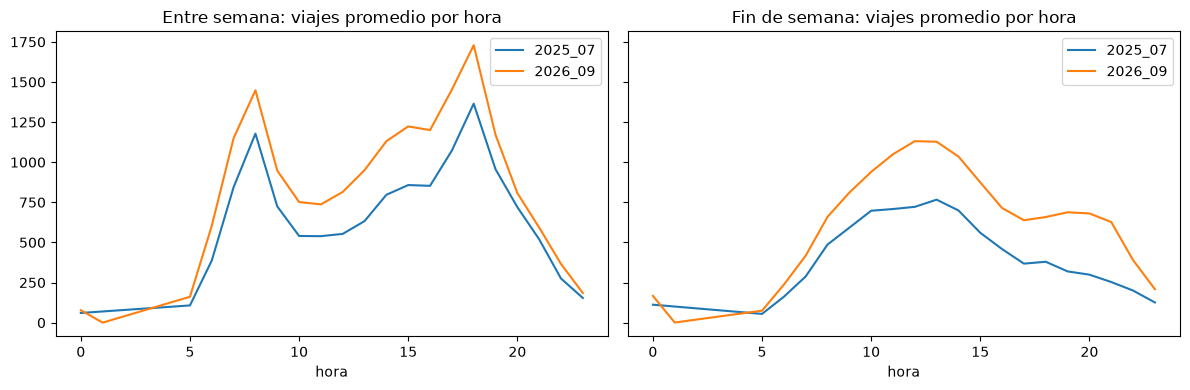

     2025_07  2026_09
lun  12502.0  17983.0
mar  13303.0  18168.0
mié  13913.0  16257.0
jue  13188.0  16646.0
vie  12537.0  18595.0
sáb   8628.0  13812.0
dom   7876.0  12446.0


In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for k, df in viajes.items():
    t = df["inicio_viaje"].dropna()
    finde = t.dt.dayofweek >= 5
    for ax, mask in [(axes[0], ~finde), (axes[1], finde)]:
        n_dias = t[mask].dt.normalize().nunique()
        (t[mask].dt.hour.value_counts().sort_index() / n_dias).plot(ax=ax, label=k)
axes[0].set_title("Entre semana: viajes promedio por hora")
axes[1].set_title("Fin de semana: viajes promedio por hora")
for ax in axes:
    ax.set_xlabel("hora")
    ax.legend()
plt.tight_layout()
plt.show()

por_dia = pd.DataFrame({
    k: df.groupby(df["inicio_viaje"].dt.normalize()).size().groupby(lambda d: d.dayofweek).mean()
    for k, df in viajes.items()
}).round(0)
por_dia.index = ["lun", "mar", "mié", "jue", "vie", "sáb", "dom"]
print(por_dia)

## Tabla estación-hora (base común de P1, P2 y P3)
Salidas por estación de origen y hora de inicio, llegadas por estación de destino y hora de fin; las horas sin viajes quedan en 0.

In [18]:
def tabla_estacion_hora(df):
    sal = df.groupby(["origen_id", df["inicio_viaje"].dt.floor("h")]).size()
    lle = df.groupby(["destino_id", df["fin_viaje"].dt.floor("h")]).size()
    sal.index.names = ["estacion_id", "hora"]
    lle.index.names = ["estacion_id", "hora"]
    estaciones = sorted(set(df["origen_id"]) | set(df["destino_id"]))
    horas = pd.date_range(df["inicio_viaje"].min().floor("h"), df["inicio_viaje"].max().floor("h"), freq="h")
    idx = pd.MultiIndex.from_product([estaciones, horas], names=["estacion_id", "hora"])
    t = pd.DataFrame({"salidas": sal, "llegadas": lle}).reindex(idx).fillna(0).astype(int)
    t["flujo_neto"] = t["llegadas"] - t["salidas"]
    return t.reset_index()


eh = tabla_estacion_hora(viajes["2025_07"])
print(f"filas estación-hora: {len(eh):,}")
print("% de horas con 0 salidas:", round((eh["salidas"] == 0).mean() * 100, 1))
print("salidas por estación-hora:", eh["salidas"].describe(percentiles=[0.5, 0.9, 0.99]).round(2).to_dict())

filas estación-hora: 273,048
% de horas con 0 salidas: 53.1
salidas por estación-hora: {'count': 273048.0, 'mean': 1.35, 'std': 2.43, 'min': 0.0, '50%': 0.0, '90%': 4.0, '99%': 11.0, 'max': 71.0}


## Calibración de la etiqueta de P2
Para cada ventana W y umbrales α (vaciarse) y β (llenarse), con α < β, porcentaje de estación-horas en riesgo según el flujo neto acumulado relativo a la capacidad.

In [19]:
eh = eh.merge(nom[["estacion_id", "capacidad"]], on="estacion_id", how="left")
print("estaciones sin capacidad:", eh.loc[eh["capacidad"].isna(), "estacion_id"].nunique())
eh = eh[eh["capacidad"] > 0].sort_values(["estacion_id", "hora"]).reset_index(drop=True)

g = eh.groupby("estacion_id")["flujo_neto"]
filas = []
for W in [2, 3, 4]:
    acum = pd.concat([g.shift(-j) for j in range(W)], axis=1).cumsum(axis=1)
    ok = acum.notna().all(axis=1)
    fmin = acum.min(axis=1)[ok] / eh.loc[ok, "capacidad"]
    fmax = acum.max(axis=1)[ok] / eh.loc[ok, "capacidad"]
    for a in [0.2, 0.3, 0.4, 0.5]:
        for b in [0.4, 0.5, 0.6, 0.7]:
            if b <= a:
                continue
            vac, lle = fmin <= -a, fmax >= b
            filas.append({"W": W, "alfa": a, "beta": b, "%vaciarse": vac.mean() * 100,
                          "%llenarse": lle.mean() * 100, "%positivos": (vac | lle).mean() * 100})
print(pd.DataFrame(filas).round(2).to_string(index=False))

estaciones sin capacidad: 0
 W  alfa  beta  %vaciarse  %llenarse  %positivos
 2   0.2   0.4       8.81       1.91       10.72
 2   0.2   0.5       8.81       0.91        9.71
 2   0.2   0.6       8.81       0.55        9.35
 2   0.2   0.7       8.81       0.29        9.09
 2   0.3   0.4       3.60       1.91        5.52
 2   0.3   0.5       3.60       0.91        4.51
 2   0.3   0.6       3.60       0.55        4.15
 2   0.3   0.7       3.60       0.29        3.89
 2   0.4   0.5       1.93       0.91        2.84
 2   0.4   0.6       1.93       0.55        2.48
 2   0.4   0.7       1.93       0.29        2.22
 2   0.5   0.6       0.88       0.55        1.43
 2   0.5   0.7       0.88       0.29        1.17
 3   0.2   0.4      13.15       3.56       16.68
 3   0.2   0.5      13.15       1.86       14.99
 3   0.2   0.6      13.15       1.18       14.32
 3   0.2   0.7      13.15       0.62       13.77
 3   0.3   0.4       6.17       3.56        9.72
 3   0.3   0.5       6.17       1.86     

## Hallazgos
- **Formato:** ambos meses tienen las mismas 8 columnas, pero distinta codificación (jul-2025 en latin-1, sep-2026 en UTF-8 con BOM). La ingesta debe probar ambas.
- **Tamaño:** 368,186 viajes en jul-2025 y 490,056 en sep-2026 (+33 %). Estaciones con viajes: 367 y 468 de las 484 de la nomenclatura; ninguna fuera de ella. El sistema creció, así que el test incluye estaciones nuevas y más demanda.
- **Calidad:** 758 `viaje_id` duplicados en sep-2026; 2 y 1 viajes de más de 24 h; nulos solo en género y año de nacimiento, que no se usan.
- **Patrón semanal:** en jul-2025, entre 12.5 y 13.9 mil viajes diarios entre semana contra 7.9–8.6 mil en fin de semana; en sep-2026, 16.3–18.6 mil contra 12.4–13.8 mil. Con dos meses no se puede separar la estacionalidad anual del crecimiento.
- **Patrón horario:** entre semana hay picos a las 8 h y de 17 a 19 h; en fin de semana el uso se concentra a mediodía.
- **P1:** 273,048 estación-horas en jul-2025; el 53.1 % tiene 0 salidas (mediana 0, p90 4, p99 11). Por eso se usan MAE y RMSE y no MAPE.
- **P2:** con W = 3 h, α = 0.3 y β = 0.6, el 7.34 % de las estación-horas queda en riesgo (6.17 % de vaciarse y 1.18 % de llenarse).